# Pass archive v1: what data we have

One DuckDB file, `data/passarchive_v1/release/passarchive_v1.duckdb`, holds **what the surveys reported** and **what
Sentinel-2 observed** for Kenya, Malawi and Zimbabwe. Nothing is filtered: every survey row, every satellite pass
(cloudy or not) and every band, as digital numbers exactly as published. Cloud mask, monthly rule, cleaning and split
are choices that each person makes later, on top of this file.

This notebook only reads the file. Every number and figure below is computed from it when the notebook runs
(about one minute). Sections: 1 the file in numbers, 2 surveys, 3 coordinates, 4 satellite passes, 5 coverage by
month, 6 one field with all its passes, 7 how to get X and y, 8 what to handle with care, 9 checks.

In [1]:
import json
import os
from pathlib import Path

import duckdb
import matplotlib as mpl
import matplotlib.patheffects
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display
from matplotlib.colors import LinearSegmentedColormap

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RELEASE = Path(os.environ.get("PASSARCHIVE_RELEASE") or REPO / "data" / "passarchive_v1" / "release")
DB = RELEASE / "passarchive_v1.duckdb"
con = duckdb.connect(str(DB), read_only=True)        # read-only: this notebook writes nothing


def sql(text, *values):
    return con.execute(text, list(values)).df()


def show(table):
    """Print a table without its index: thousands separators, years as they are, yes/no for true/false."""
    def text(value, year):
        if isinstance(value, (bool, np.bool_)):
            return "yes" if value else "no"
        if isinstance(value, (int, np.integer)):
            return str(value) if year else f"{value:,}"
        if isinstance(value, (float, np.floating)):
            if np.isnan(value):
                return ""
            if float(value).is_integer():
                return f"{value:.0f}" if year else f"{value:,.0f}"
            return f"{value:,.3f}" if abs(value) < 1 else f"{value:,.2f}"
        return "" if value is None else str(value)
    shown = pd.DataFrame({name: [text(value, "year" in str(name)) for value in table[name]] for name in table.columns})
    display(HTML(shown.to_html(index=False, border=0, justify="left")))


# One visual system (the one of notebooks/midterm_figures.ipynb): text inks, hairlines, one hue per country.
INK, INK2, MUTED, GRID, AXIS = "#1b1b1a", "#52514e", "#898781", "#e6e5df", "#bdbcb3"
COUNTRY = {"KEN": ("Kenya", "#2a78d6"), "MWI": ("Malawi", "#1baf7a"), "ZWE": ("Zimbabwe", "#eb6834")}
MAGNITUDE = LinearSegmentedColormap.from_list("magnitude", ["#f3f6fb", "#a9c6ec", "#3f7fd0", "#143d73"])
FULL = 7.2                                           # figure width in inches
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 7.5,
    "axes.titlesize": 8.2, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 7.5,
    "axes.labelcolor": INK2, "xtick.labelsize": 7, "ytick.labelsize": 7, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "text.color": INK, "grid.color": GRID, "grid.linewidth": 0.5,
    "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 7, "figure.dpi": 160, "savefig.dpi": 300,
})

# Two conventions used in the examples below. Both are choices, not part of the data.
CLEAR = "(4, 5)"    # scene classification: 4 vegetation, 5 bare soil = "clear at the field"
SEASON = {"KEN": "February to September of the harvest year",
          "MWI": "October of the year before to June", "ZWE": "October of the year before to June"}
print(DB.name, f"{DB.stat().st_size / 1e9:.2f} GB")

passarchive_v1.duckdb 2.68 GB


## 1. The file in numbers

In [2]:
info = json.loads(sql("select details_json from build_info").details_json[0])
rows, status = info["row_counts"], info["passes_by_sample_status"]
checksum = (RELEASE / "SHA256SUMS").read_text().split()[0] if (RELEASE / "SHA256SUMS").exists() else "not found"
usable = int(sql("select count(*) n from fields where usable_at_field_scale").n[0])
show(pd.DataFrame([
    ("file size", f"{DB.stat().st_size / 1e9:.2f} GB ({DB.stat().st_size:,} bytes)"),
    ("built (UTC)", info["built_at_utc"]),
    ("SHA-256", checksum),
    ("original survey rows (table source_records)", rows["source_records"]),
    ("field-seasons: one crop on one field in one season (fields)", rows["fields"]),
    ("field-seasons with coordinates usable at field scale", usable),
    ("Sentinel-2 product versions listed (scenes)", rows["scenes"]),
    ("passes listed: field-season x satellite pass over its tile (passes)", rows["passes"]),
    ("passes with all Level-2A bands read at the field", status.get("sampled_all_bands", 0)),
    ("native pixels kept for the Malawi polygons (pixel_samples)", rows["pixel_samples"]),
], columns=["", "value"]))

,value
file size,"2.68 GB (2,678,075,392 bytes)"
built (UTC),2026-11-19T14:46:35+00:00
SHA-256,7a02a6fe7b0147dad9ba1ac7380a29224ecf6261847173182c11ece64990e4bf
original survey rows (table source_records),"42,379"
field-seasons: one crop on one field in one season (fields),"35,510"
field-seasons with coordinates usable at field scale,"33,844"
Sentinel-2 product versions listed (scenes),"66,085"
passes listed: field-season x satellite pass over its tile (passes),"8,248,916"
passes with all Level-2A bands read at the field,"5,611,314"
native pixels kept for the Malawi polygons (pixel_samples),"259,808,279"


## 2. Surveys: what the field teams reported

One row per country, harvest year, source and crop. **measured** = a yield above zero; **zero** = a recorded zero or
a stated crop failure (`labels.label_status` and `labels.zero_evidence` say which); **no yield** = the source has
no number. **fold 0** = field-seasons in fold 0 of a frozen `s1_cc2km` split (`fields.fold0_reserved`): the project
rule keeps them out of development.

In [3]:
SOURCE = """case f.dataset when 'one_acre_fund_full' then 'One Acre Fund, workbook'
            when 'one_acre_fund_curated' then 'One Acre Fund, curated file (rows with no workbook twin)'
            when 'zimbabwe' then 'Lacuna Fund / PULA' when 'vision_guided_yield_estimation' then 'Vision-guided dataset'
            else 'FAO / NASA Harvest crop cuts' end"""
NAME = "case f.country_iso3 when 'KEN' then 'Kenya' when 'MWI' then 'Malawi' else 'Zimbabwe' end"
surveys = sql(f"""
    select {NAME} as country, cast(cast(f.harvest_year as integer) as varchar) as "harvest year", {SOURCE} as source, f.crop,
           count(*) as "field-seasons", count(*) filter (where f.usable_at_field_scale) as "with coordinates",
           count(*) filter (where l.label_status = 'measured_positive') as measured,
           count(*) filter (where l.label_status in ('recorded_zero', 'verified_crop_failure')) as zero,
           count(*) filter (where l.label_status in ('not_answered', 'not_measured')) as "no yield",
           cast(sum(f.fold0_reserved::int) as integer) as "fold 0"
    from fields f join labels l using (fs_key) group by all order by 1, 2, 3, 4""")
show(surveys)
total = surveys[["field-seasons", "with coordinates", "measured", "zero", "no yield", "fold 0"]].sum()
display(Markdown("**All together:** " + ", ".join(f"{int(value):,} {name}" for name, value in total.items()) + "."))

country,harvest year,source,crop,field-seasons,with coordinates,measured,zero,no yield,fold 0
Kenya,2016,"One Acre Fund, curated file (rows with no workbook twin)",maize,58,0,56,2,0,0
Kenya,2016,"One Acre Fund, workbook",maize,"3,876","3,770","3,825",51,0,0
Kenya,2017,"One Acre Fund, curated file (rows with no workbook twin)",maize,11,0,7,4,0,0
Kenya,2017,"One Acre Fund, workbook",maize,"3,991","3,991","3,942",49,0,0
Kenya,2018,"One Acre Fund, curated file (rows with no workbook twin)",maize,35,0,35,0,0,0
Kenya,2018,"One Acre Fund, workbook",maize,"4,245","4,231","4,227",18,0,0
Kenya,2019,"One Acre Fund, curated file (rows with no workbook twin)",maize,77,0,57,20,0,0
Kenya,2019,"One Acre Fund, workbook",maize,"5,372","5,348","5,251",121,0,366
Kenya,2020,"One Acre Fund, curated file (rows with no workbook twin)",maize,208,0,191,17,0,0
Kenya,2020,"One Acre Fund, workbook",maize,"6,190","5,819","6,103",87,0,430


**All together:** 35,510 field-seasons, 33,844 with coordinates, 31,687 measured, 2,292 zero, 1,531 no yield, 1,822 fold 0.

**Yields.** Median (dot), middle half (thick line) and 5th to 95th percentile (thin line), in kg/ha as stored in
`labels.yield_kg_ha`. Development field-seasons only (fold 0 is not looked at). Zimbabwe 2024 is drawn twice: all
rows, and without the recorded zeros, because most of its zeros are "not measured", not a real zero.

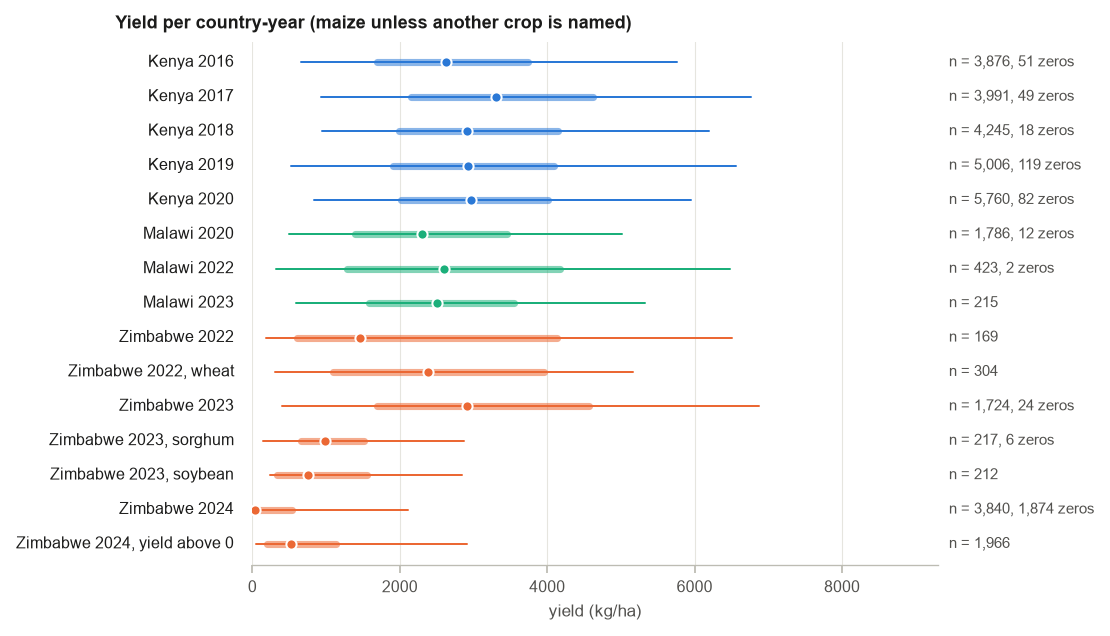

In [4]:
yields = sql("""
    select f.country_iso3 as c, cast(f.harvest_year as integer) as y, f.crop, false as positive_only, count(*) as n,
           cast(sum((l.yield_kg_ha = 0)::int) as integer) as zeros, median(l.yield_kg_ha) as p50,
           quantile_cont(l.yield_kg_ha, [0.05, 0.25, 0.75, 0.95]) as q
    from fields f join labels l using (fs_key)
    where l.yield_kg_ha is not null and not f.fold0_reserved and f.dataset <> 'one_acre_fund_curated' group by all
    union all
    select f.country_iso3, 2024, f.crop, true, count(*), 0, median(l.yield_kg_ha), quantile_cont(l.yield_kg_ha, [0.05, 0.25, 0.75, 0.95])
    from fields f join labels l using (fs_key)
    where l.yield_kg_ha > 0 and not f.fold0_reserved and f.dataset = 'vision_guided_yield_estimation' group by all
    order by 1, 2, 3, 4""")
fig, ax = plt.subplots(figsize=(FULL, 0.24 * len(yields) + 0.7))
for position, row in enumerate(yields.itertuples()):
    name, hue = COUNTRY[row.c]
    ax.plot([row.q[0], row.q[3]], [position, position], color=hue, lw=0.9, solid_capstyle="round")
    ax.plot([row.q[1], row.q[2]], [position, position], color=hue, lw=3.2, solid_capstyle="round", alpha=0.55)
    ax.plot(row.p50, position, "o", ms=4.6, mfc=hue, mec="white", mew=0.9, zorder=5)
    label = f"{name} {row.y}" + ("" if row.crop == "maize" else f", {row.crop}") + (", yield above 0" if row.positive_only else "")
    ax.text(-250, position, label, ha="right", va="center", fontsize=7, color=INK)
    note = f"n = {row.n:,}" + (f", {row.zeros:,} zeros" if row.zeros else "")
    ax.text(9450, position, note, ha="left", va="center", fontsize=6.6, color=INK2)
ax.set(xlim=(0, 9300), ylim=(len(yields) - 0.4, -0.6), xlabel="yield (kg/ha)", yticks=[])
ax.xaxis.grid(True)
ax.spines["left"].set_visible(False)
ax.set_title("Yield per country-year (maize unless another crop is named)", x=-0.2)
fig.subplots_adjust(left=0.235, right=0.83, top=0.9, bottom=0.14)
plt.show()

## 3. Coordinates

A field-season can be sampled only if its location is usable at field scale: a GPS point taken at the field, or a
surveyed field outline (Malawi crop cuts). Records without a usable location stay in the file, with the reason.
Some locations are used by several field-seasons (the same coordinates in several rows of a source); their pixel
values are stored once.

In [5]:
quality = sql(f"""
    select {NAME} as country,
           case f.location_quality when 'field_point' then 'GPS point at the field: used'
                when 'field_polygon' then 'surveyed field outline (polygon): used'
                when 'missing' then 'no coordinates in the source: not sampled'
                when 'rounded_point' then 'point rounded and shifted by the provider (about 160 m): not sampled'
                else 'coordinates outside the country: not sampled' end as location,
           count(*) as "field-seasons"
    from fields f group by all order by 1, 3 desc""")
show(quality)
places = sql(f"""select {NAME.replace('f.', '')} as country, count(*) as "distinct locations",
                        cast(sum((n_field_seasons > 1)::int) as integer) as "used by several field-seasons",
                        round(min(latitude), 2) as "south", round(max(latitude), 2) as "north",
                        round(min(longitude), 2) as "west", round(max(longitude), 2) as "east"
                 from locations group by all order by 1""")
show(places)

country,location,field-seasons
Kenya,GPS point at the field: used,"23,159"
Kenya,no coordinates in the source: not sampled,514
Kenya,point rounded and shifted by the provider (about 160 m): not sampled,389
Kenya,coordinates outside the country: not sampled,1
Malawi,GPS point at the field: used,"1,832"
Malawi,surveyed field outline (polygon): used,796
Malawi,no coordinates in the source: not sampled,762
Zimbabwe,GPS point at the field: used,"8,057"


country,distinct locations,used by several field-seasons,south,north,west,east
Kenya,"22,279",719,-1.16,1.23,34,37.83
Malawi,"2,613",10,-16.16,-10.98,33.21,35.78
Zimbabwe,"8,047",10,-21.85,-16.13,27.11,33.04


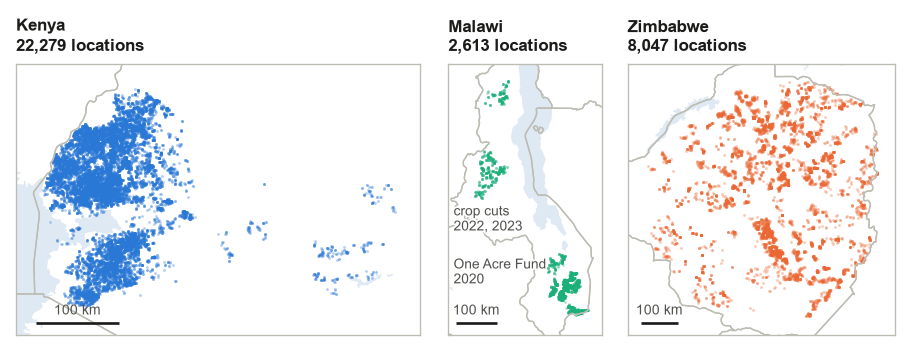

In [6]:
import shapefile  # pyshp; the country outlines are optional (public Natural Earth files, see notebooks/midterm_get_basemap.py)

points = sql("select country_iso3 as c, longitude as lon, latitude as lat, geometry_type as kind, dataset from locations l "
             "join (select loc_key, any_value(dataset) dataset from fields group by 1) using (loc_key)")
BASEMAP = REPO / "data" / "imagery" / "basemap" / "naturalearth"


def outlines(folder, key=None, wanted=None):
    """Polygon rings of a Natural Earth layer as arrays of (lon, lat); empty when the files are not there."""
    path = BASEMAP / folder / f"{folder}.shp"
    if not path.exists():
        return []
    reader, rings = shapefile.Reader(str(path)), []
    names = [field[0] for field in reader.fields[1:]]
    for item in reader.iterShapeRecords():
        if wanted is None or item.record[names.index(key)] in wanted:
            parts = [*item.shape.parts, len(item.shape.points)]
            rings += [np.array(item.shape.points[a:b]) for a, b in zip(parts[:-1], parts[1:])]
    return rings


borders, lakes = outlines("ne_10m_admin_0_countries"), outlines("ne_10m_lakes")
frames = {"KEN": (33.7, 38.1, -1.45, 1.5), "MWI": (32.6, 36.1, -16.6, -10.6), "ZWE": (26.6, 33.5, -22.3, -15.7)}
widths = [(e - w) * np.cos(np.radians((s + n) / 2)) / (n - s) for w, e, s, n in frames.values()]
fig, axes = plt.subplots(1, 3, figsize=(FULL, FULL / sum(widths) * 0.93), gridspec_kw={"width_ratios": widths, "wspace": 0.06})
for ax, (code_, (west, east, south, north)) in zip(axes, frames.items()):
    name, hue = COUNTRY[code_]
    for ring in lakes:
        ax.fill(ring[:, 0], ring[:, 1], color="#dfe9f3", lw=0)
    for ring in borders:
        ax.plot(ring[:, 0], ring[:, 1], color=AXIS, lw=0.6)
    here = points[points.c == code_]
    ax.scatter(here.lon, here.lat, s=1.6, color=hue, alpha=0.35, linewidths=0, rasterized=True)
    ax.set(xlim=(west, east), ylim=(south, north), xticks=[], yticks=[])
    ax.set_aspect(1 / np.cos(np.radians((south + north) / 2)))
    for side in ax.spines.values():
        side.set(visible=True, color=AXIS, linewidth=0.6)
    ax.set_title(f"{name}\n{len(here):,} locations", fontsize=7.8, linespacing=1.25)
    bar = 100 / (111.32 * np.cos(np.radians((south + north) / 2)))          # 100 km in degrees of longitude
    x0, y0 = west + 0.05 * (east - west), south + 0.045 * (north - south)
    ax.plot([x0, x0 + bar], [y0, y0], color=INK, lw=1.2, solid_capstyle="butt")
    ax.text(x0 + bar / 2, y0 + 0.02 * (north - south), "100 km", ha="center", va="bottom", fontsize=6.2, color=INK2)
note = {"fontsize": 6.2, "color": INK2, "linespacing": 1.15,
        "path_effects": [mpl.patheffects.withStroke(linewidth=1.6, foreground="white")]}
axes[1].text(32.72, -13.7, "crop cuts\n2022, 2023", ha="left", va="top", **note)
axes[1].text(32.72, -14.85, "One Acre Fund\n2020", ha="left", va="top", **note)
plt.show()

**Does the pixel at the coordinate look like a field?** A label-free check: the clear-sky NDVI of the harvest year at
each location. A pixel that never turns green, or does not change over the year, is probably not on a crop (a roof, a
road, bare ground). The source says that some One Acre Fund points were taken at the homestead, not in the field.
Zimbabwe 2024 was a drought year with many failed crops, so its low share is not only a coordinate problem.

In [7]:
greenness = sql(f"""
    with field as (select fs_key, count(*) as clear_passes, quantile_cont(ndvi, 0.95) as high, quantile_cont(ndvi, 0.05) as low
                   from v_ndvi_v1 where window_kind = 'current' and scl in {CLEAR} group by fs_key)
    select {NAME} as country, cast(cast(f.harvest_year as integer) as varchar) as "harvest year", count(*) as "field-seasons with coordinates",
           cast(median(v.clear_passes) as integer) as "clear passes in the harvest year (median)",
           round(median(v.high), 2) as "NDVI peak (median)",
           count(*) filter (where v.high < 0.3) as "never green (peak below 0.3)",
           round(100.0 * count(*) filter (where v.high >= 0.3 and v.high - v.low >= 0.15) / count(*), 1) as "green and seasonal (%)"
    from fields f left join field v using (fs_key) where f.usable_at_field_scale group by all order by 1, 2""")
show(greenness)

country,harvest year,field-seasons with coordinates,clear passes in the harvest year (median),NDVI peak (median),never green (peak below 0.3),green and seasonal (%)
Kenya,2016,"3,770",19,0.730,34,97.90
Kenya,2017,"3,991",35,0.760,14,98.90
Kenya,2018,"4,231",44,0.740,50,98.60
Kenya,2019,"5,348",47,0.750,175,96.40
Kenya,2020,"5,819",45,0.770,87,94.90
Malawi,2020,"1,832",74,0.680,8,99.60
Malawi,2022,529,48,0.640,1,99.80
Malawi,2023,267,42,0.610,0,100
Zimbabwe,2022,473,72,0.740,3,99.40
Zimbabwe,2023,"2,529",76,0.600,22,99.10


## 4. Sentinel-2: every pass

For each usable location the file lists **every** Sentinel-2 pass over its tile in two calendar years: the harvest
year (`current`) and the year before (`previous`). `passes.sample_status` says what happened to each pass.

In [8]:
MEANING = {
    "sampled_all_bands": "all Level-2A bands and quality layers read at the native pixel (cloudy passes included)",
    "outside_swath_per_catalogue": "the tile holds the field, but the sensor did not see it on that pass (not read)",
    "sampled_nodata": "read; the pixel holds no data",
    "not_sampled_no_public_file": "listed; no copy exists that can be read without an account",
    "sampled_10m_bands": "only B02, B03, B04, B08, taken from the old image chips",
    "not_sampled_yet": "listed; not read yet",
}
passes = sql("select sample_status, count(*) as passes from passes group by 1 order by 2 desc")
passes["share (%)"] = (100 * passes.passes / passes.passes.sum()).round(1)
passes["meaning"] = passes.sample_status.map(MEANING)
show(passes)

sample_status,passes,share (%),meaning
sampled_all_bands,"5,611,314",68,all Level-2A bands and quality layers read at the native pixel (cloudy passes included)
outside_swath_per_catalogue,"2,483,065",30.10,"the tile holds the field, but the sensor did not see it on that pass (not read)"
not_sampled_no_public_file,"81,561",1,listed; no copy exists that can be read without an account
sampled_nodata,"72,555",0.900,read; the pixel holds no data
sampled_10m_bands,421,0,"only B02, B03, B04, B08, taken from the old image chips"


**Where the values come from.** Three public copies of the Level-2A products were read. They carry the same bands;
they differ in processing version and in the quality layers. `scl` (scene classification) exists for every sample;
the cloud and snow probability (`cld`, `snw`) only for Collection 1. The +1000 offset of newer processing versions
is recorded per scene (`dn_add_offset`) and applied once in the view `v_reflectance`.

In [9]:
sources = sql("""
    with item as (select item_id, any_value(provider) as provider, any_value(collection) as collection from scene_items group by 1)
    select case when i.collection = 'sentinel-2-c1-l2a' then 'Earth Search, Collection 1'
                when i.collection = 'sentinel-2-l2a' then 'Earth Search, older collection' else 'Planetary Computer' end as source,
           cast(min(g.year) as varchar) || ' to ' || cast(max(g.year) as varchar) as years,
           count(*) as "samples (location x scene)", string_agg(distinct s.processing_baseline, ', ' order by s.processing_baseline) as "processing versions",
           count(x.b01) = count(*) as "all 12 bands", count(x.scl) = count(*) as scl, count(x.cld) = count(*) as "cloud probability"
    from pass_samples x join item i using (item_id) join scenes s using (scene_key) join granules g on g.granule_key = x.granule_key
    where x.read_route = 'direct_cog_all_bands' group by 1 order by 3 desc""")
show(sources)

source,years,samples (location x scene),processing versions,all 12 bands,scl,cloud probability
"Earth Search, Collection 1",2018 to 2024,"6,662,918","05.00, 05.09, 05.10, 05.11",yes,yes,yes
"Earth Search, older collection",2017 to 2024,"3,226,312","00.01, 02.08, 02.11, 03.01, 04.00, 05.09, 05.10",yes,yes,no
Planetary Computer,2015 to 2022,"867,687","02.12, 03.00, 04.00, 05.10",yes,yes,no


## 5. Coverage by month

Rows are country-years, columns the 24 calendar months of the two windows. The upper panel counts the passes with
band values per field and month; the lower panel counts those that are clear at the field (scene classification 4 or
5: one possible rule). The outline marks the main growing season. Kenya 2016 starts late: Sentinel-2 took its first
images in the middle of 2015.

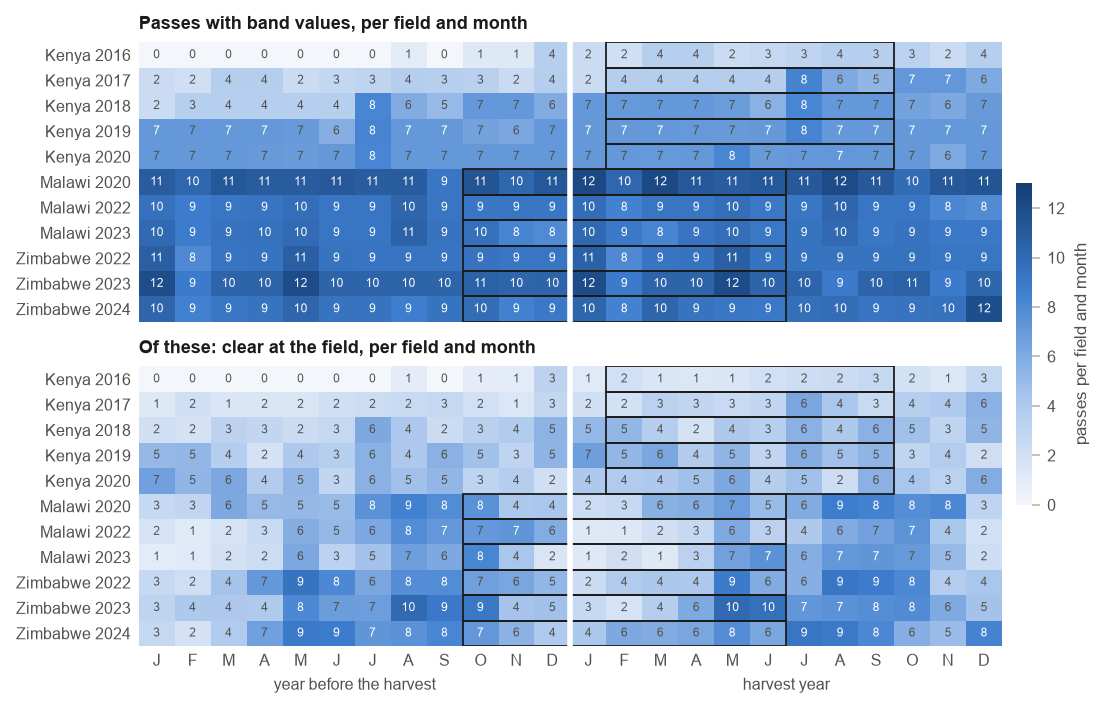

In [10]:
cover = sql(f"""
    with clear as (select p.fs_key, p.window_kind, p.month, count(*) filter (where x.scl in {CLEAR}) as n
                   from passes p join pass_samples x on x.loc_key = p.loc_key and x.granule_key = p.granule_key
                   where p.sample_status = 'sampled_all_bands' group by all)
    select f.country_iso3 as c, cast(f.harvest_year as integer) as y, m.window_kind, m.month,
           avg(m.n_sampled_all_bands) as with_values, avg(coalesce(k.n, 0)) as clear
    from coverage_months m join fields f using (fs_key) left join clear k using (fs_key, window_kind, month)
    where f.usable_at_field_scale group by all""")
cover["column"] = cover.month - 1 + 12 * (cover.window_kind == "current")
order = sorted(set(zip(cover.c, cover.y)))
fig, axes = plt.subplots(2, 1, figsize=(FULL, 4.9), sharex=True, gridspec_kw={"hspace": 0.16})
top = float(np.ceil(cover.with_values.max()))
for ax, measure, title in zip(axes, ("with_values", "clear"), ("Passes with band values, per field and month",
                                                               "Of these: clear at the field, per field and month")):
    grid = cover.pivot_table(index=["c", "y"], columns="column", values=measure).reindex(order)
    image = ax.imshow(grid.to_numpy(), cmap=MAGNITUDE, vmin=0, vmax=top, aspect="auto")
    for (r, k), value in np.ndenumerate(grid.to_numpy()):
        ax.text(k, r, f"{value:.0f}", ha="center", va="center", fontsize=5.6, color="white" if value > 0.55 * top else INK2)
    for r, (c, _) in enumerate(order):                       # outline of the main growing season
        first, last = (13, 20) if c == "KEN" else (9, 17)
        ax.add_patch(plt.Rectangle((first - 0.5, r - 0.5), last - first + 1, 1, fill=False, ec=INK, lw=0.8))
    ax.set_yticks(range(len(order)), [f"{COUNTRY[c][0]} {y}" for c, y in order])
    ax.set_xticks(range(24), list("JFMAMJJASOND") * 2)
    ax.tick_params(length=0)
    ax.axvline(11.5, color="white", lw=2.5)
    ax.set_title(title)
    for side in ax.spines.values():
        side.set_visible(False)
axes[1].text(5.5, len(order) + 0.75, "year before the harvest", ha="center", va="top", fontsize=7, color=INK2)
axes[1].text(17.5, len(order) + 0.75, "harvest year", ha="center", va="top", fontsize=7, color=INK2)
bar = fig.colorbar(image, ax=axes, fraction=0.018, pad=0.015)
bar.set_label("passes per field and month")
bar.outline.set_visible(False)
plt.show()

## 6. One field, every pass

One development field per country, all passes of its two calendar years. Grey: every pass with values, also the
cloudy ones (cloud lowers the NDVI). Colour: the passes that are clear at the field. Which passes to keep, and how to
make months of them, is the choice of the person who models.

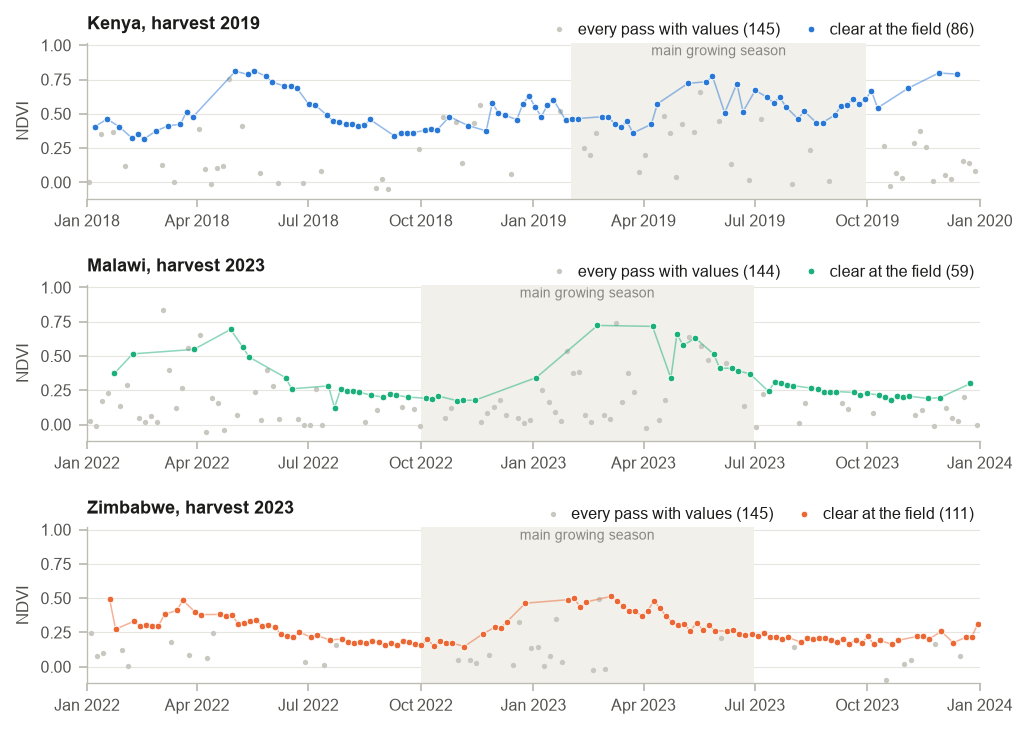

country,harvest year,field_season_id,yield (kg/ha)
Kenya,2019,fs_0147928f7e80c682,"2,604.10"
Malawi,2023,fs_d4d170d12846eabc,"3,720"
Zimbabwe,2023,fs_0010e5703744617c,"1,946.88"


In [11]:
examples = sql("""
    select field_season_id, country_iso3 as c, cast(harvest_year as integer) as y, yield_kg_ha
    from field_xy where not fold0_reserved and crop = 'maize' and yield_kg_ha > 1500
      and legacy_cohort in ('kenya_oaf_2019_2020', 'malawi_2023', 'zimbabwe_lacuna_2022_2023') and harvest_year in (2019, 2023)
    qualify row_number() over (partition by legacy_cohort order by abs(n_passes_all_bands - 145), field_season_id) = 1 order by 2""")
fig, axes = plt.subplots(3, 1, figsize=(FULL, 5.2), gridspec_kw={"hspace": 0.55})
for ax, field in zip(axes, examples.itertuples()):
    name, hue = COUNTRY[field.c]
    series = sql("""select sensing_time_utc as t, scl, (b08 - b04) / nullif(b08 + b04 + 2 * dn_add_offset, 0) as ndvi
                    from master where field_season_id = ? and sample_status = 'sampled_all_bands' and b04 > 0 order by 1""",
                 field.field_season_id)
    clear = series[series.scl.isin([4, 5])]
    start = pd.Timestamp(field.y, 2, 1) if field.c == "KEN" else pd.Timestamp(field.y - 1, 10, 1)
    end = pd.Timestamp(field.y, 9, 30) if field.c == "KEN" else pd.Timestamp(field.y, 6, 30)
    ax.axvspan(start, end, color="#f1f0ea", lw=0)
    ax.text(start + (end - start) / 2, 1.0, "main growing season", ha="center", va="top", fontsize=6.2, color=MUTED)
    ax.plot(series.t, series.ndvi, "o", ms=2.4, color="#c9c8c0", mew=0, label=f"every pass with values ({len(series)})")
    ax.plot(clear.t, clear.ndvi, "-", lw=0.7, color=hue, alpha=0.5)
    ax.plot(clear.t, clear.ndvi, "o", ms=3.0, color=hue, mec="white", mew=0.4, label=f"clear at the field ({len(clear)})")
    ax.set(ylim=(-0.12, 1.02), ylabel="NDVI", xlim=(pd.Timestamp(field.y - 1, 1, 1), pd.Timestamp(field.y + 1, 1, 1)))
    ax.yaxis.grid(True)
    ax.xaxis.set_major_locator(mpl.dates.MonthLocator(bymonth=(1, 4, 7, 10)))
    ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b %Y"))
    ax.set_title(f"{name}, harvest {field.y}")
    ax.legend(loc="lower right", ncols=2, bbox_to_anchor=(1.0, 0.99), handletextpad=0.2, columnspacing=1.0, borderaxespad=0)
plt.show()
show(examples.assign(country=[COUNTRY[c][0] for c in examples.c])
     .rename(columns={"y": "harvest year", "yield_kg_ha": "yield (kg/ha)"})[["country", "harvest year", "field_season_id", "yield (kg/ha)"]])

## 7. How to get X and y

Three ways into the same data. Band columns are digital numbers; `v_reflectance`, `v_ndvi_v1` and `v_gcvi_v1` apply
scale and offset. `DICTIONARY.md` beside the file lists every table and column.

**a. One row per field: `field_xy`.** The yield, and `passes` = the list of all passes with all bands.

In [12]:
one = sql("select * from field_xy where legacy_cohort = 'malawi_2023' and not fold0_reserved order by field_season_id limit 1")
facts = one.drop(columns="passes").astype({"harvest_year": int}).astype({"harvest_year": str})
show(facts.T.reset_index().set_axis(["column", "value"], axis=1))
passes_of_field = pd.DataFrame(list(one.passes[0]))
print(f"passes of this field: {len(passes_of_field)} rows x {passes_of_field.shape[1]} columns")
show(passes_of_field[passes_of_field.sample_status == "sampled_all_bands"]
     [["sensing_time_utc", "window_kind", "scene_cloud_cover_percent", "b02", "b03", "b04", "b08", "b11", "b12", "scl"]].head(5))

column,value
field_season_id,fs_072585f51d384627
dataset,malawi_2023
source_observation_id,malawi_2023:3a065807-ca17-459c-961f-9dcc714b3e2f
country_iso3,MWI
crop,maize
harvest_year,2023
latitude,-12.66
longitude,33.54
geometry_type,polygon
location_quality,field_polygon


passes of this field: 287 rows x 26 columns


sensing_time_utc,window_kind,scene_cloud_cover_percent,b02,b03,b04,b08,b11,b12,scl
2022-01-01 07:52:29,previous,75.16,"5,385.31","5,069.67","4,848.95","4,974.55","3,903.07","3,437.21",9
2022-01-03 07:43:21,previous,100,"3,787.20","3,793.02","3,817.42","4,177.27","2,932.57","2,544",9
2022-01-06 07:53:21.024000,previous,100,"7,529.96","7,662.84","7,706.33","8,108.80","2,154.79","2,564.71",9
2022-01-08 07:42:09,previous,100,"7,703.93","7,759.78","7,732.51","8,094.33","2,358.07","2,594.64",9
2022-01-11 07:52:09,previous,17.71,998.49,"1,344.60","1,748.29","2,364.25","3,925.79","3,502.64",5


**b. One row per field and pass: `master`.** Survey facts, yield, pass and all bands side by side (a view; filter it).

In [13]:
show(sql("""select field_season_id, country_iso3, crop, cast(harvest_year as integer) as harvest_year, yield_kg_ha, sensing_time_utc, sample_status,
                   scene_cloud_cover_percent, b04, b08, scl
            from master where legacy_cohort = 'zimbabwe_lacuna_2022_2023' and not fold0_reserved and year = 2023 and month = 3
            order by field_season_id, sensing_time_utc limit 6"""))

field_season_id,country_iso3,crop,harvest_year,yield_kg_ha,sensing_time_utc,sample_status,scene_cloud_cover_percent,b04,b08,scl
fs_0009c69ec1d919ee,ZWE,maize,2023,"1,344.38",2023-03-02 07:48:31.024000,sampled_all_bands,89.65,"2,632","4,236",8
fs_0009c69ec1d919ee,ZWE,maize,2023,"1,344.38",2023-03-02 07:48:31.024000,sampled_all_bands,89.79,"2,604","4,244",8
fs_0009c69ec1d919ee,ZWE,maize,2023,"1,344.38",2023-03-05 07:58:11.024000,outside_swath_per_catalogue,12.99,,,
fs_0009c69ec1d919ee,ZWE,maize,2023,"1,344.38",2023-03-07 07:47:59.025000,sampled_all_bands,56.44,"1,672","4,440",4
fs_0009c69ec1d919ee,ZWE,maize,2023,"1,344.38",2023-03-07 07:47:59.025000,sampled_all_bands,58.69,"1,702","4,504",4
fs_0009c69ec1d919ee,ZWE,maize,2023,"1,344.38",2023-03-12 07:47:11.024000,sampled_all_bands,58.88,"9,904","9,640",9


**c. Your own monthly features and a named split.** Example: the median NDVI of the clear passes per month, for the
Lacuna maize fields of harvest 2023, joined to the frozen spatial split. Change the rule in the `where` line to make
another X from the same passes. Development folds are 1 to 4; fold 0 stays out.

In [14]:
monthly = sql(f"""
    select n.field_season_id, (n.year - f.harvest_year) * 12 + n.month as month_of_harvest_year, median(n.ndvi) as ndvi
    from v_ndvi_v1 n join fields f using (fs_key)
    where f.legacy_cohort = 'zimbabwe_lacuna_2022_2023' and f.harvest_year = 2023 and f.legacy_include_primary
      and n.scl in {CLEAR}                                    -- <- the cloud rule: yours to change
    group by all""")
X = monthly.pivot(index="field_season_id", columns="month_of_harvest_year", values="ndvi").sort_index(axis=1)
y = sql("""select f.field_season_id, l.yield_kg_ha, s.fold from fields f join labels l using (fs_key) join splits s using (fs_key)
           where s.split_name = 'frozen/v2/zimbabwe_lacuna_2022_2023/s1_cc2km'""").set_index("field_season_id")
development = y[y.fold != 0].join(X, how="inner")
print(f"X: {X.shape[0]:,} fields x {X.shape[1]} months (month 1 = January of the harvest year, 0 and below = the year before)")
print(f"development rows (folds 1 to 4): {len(development):,}; months with a value per field (median): {int(X.notna().sum(axis=1).median())} of {X.shape[1]}")
show(sql("select split_name, rows from split_specs where split_name like 'frozen/v2/%' order by 1"))

X: 1,880 fields x 24 months (month 1 = January of the harvest year, 0 and below = the year before)
development rows (folds 1 to 4): 1,504; months with a value per field (median): 24 of 24


split_name,rows
frozen/v2/kenya_oaf_2019_2020/random_diag,"3,977"
frozen/v2/kenya_oaf_2019_2020/s1_cc2km,"3,977"
frozen/v2/kenya_oaf_2019_2020/s2_region,"3,977"
frozen/v2/kenya_oaf_2019_2020/temporal,"7,954"
frozen/v2/malawi_2022/random_diag,529
frozen/v2/malawi_2022/s1_cc2km,529
frozen/v2/malawi_2022/s2_region,529
frozen/v2/malawi_2022_2023/temporal_rank,888
frozen/v2/malawi_2023/random_diag,260
frozen/v2/malawi_2023/s1_cc2km,260


## 8. What to handle with care

- **No images, only numbers.** The file holds the pixel values at the fields. For a point: the one native pixel of
  each band (10, 20 or 60 m). For a Malawi polygon: `pass_samples` holds the mean of the pixels whose centre is inside,
  and `pixel_samples` holds every native pixel near the outline, so the edge rule can be changed.
- **Level-2A only.** Level-1C products are listed in `scenes`; their pixels are not read.
- **Two calendar years per field-season**: the harvest year and the year before. The main growing season of Malawi
  and Zimbabwe (October to June) lies inside them.
- **Kenya 2015 to 2017 has gaps.** Sentinel-2 started in mid 2015, with one satellite until 2017, and about 1 % of
  all passes (almost all Kenya 2015 to 2018) have no file that can be read without an account. Section 5 shows it.
- **Processing versions differ by period** (table in section 4). The same place and month read from two sources agree
  closely from 2018 on (section 9). Take care when you compare reflectance *levels* of 2015 to 2016 with later years.
- **Cloud probability exists only for Collection 1 scenes.** The scene classification `scl` exists for all.
- **A zero yield is not always a real zero.** Zimbabwe 2024 has 1,874 recorded zeros, most of them with no weight
  photo: read `labels.label_status` and `labels.zero_evidence`.
- **One Acre Fund points** are farmer-field GPS points; the provider says some were taken at the homestead. Two thirds
  of the Kenya rows are intercropped (`fields.intercropped`). The curated file is a subset of the workbook; its 389
  extra rows have no usable coordinates, and its yields were published 2.2 % too low (corrected in `yield_kg_ha`).
- **Malawi 2022 outlines** were converted from the Arc 1950 datum (operation EPSG:1113, as in data v2); the smallest
  outline holds 2 pixels of 10 m.
- **Fold 0 is reserved.** Its labels are in the file, flagged `fields.fold0_reserved`: do not train or tune on them.
- **Times are UTC.** `year` and `month` are UTC as well.
- **Sources and licences:** One Acre Fund (CC BY 4.0), Lacuna Fund / PULA Advisors (CC BY 4.0), Vision-guided yield
  dataset (CC BY 4.0), FAO / NASA Harvest Malawi crop cuts (CC BY); contains modified Copernicus Sentinel data.
  Keep these notices when you share the file (`README.md` beside it has the full list).

## 9. Checks

**Two sources, same place, same month.** Where two public copies cover the same location in the same month, the median
clear-sky reflectance should agree. A wrong +1000 offset would show as a step of 0.10.

In [15]:
agreement = sql(f"""
    with item as (select item_id, any_value(collection) as collection, any_value(dn_add_offset) as offset_dn from scene_items group by 1),
    monthly as (select x.loc_key, g.year, g.month, i.collection, count(*) as n,
                       median((x.b04 + i.offset_dn) / 10000.0) as red, median((x.b08 + i.offset_dn) / 10000.0) as nir
                from pass_samples x join granules g using (granule_key) join item i using (item_id)
                where x.read_route = 'direct_cog_all_bands' and x.scl in {CLEAR} and x.b04 > 0 group by all)
    select case when a.collection = 'sentinel-2-c1-l2a' then 'Earth Search Collection 1' else 'Planetary Computer' end
           || ' minus Earth Search older collection' as pair, cast(a.year as varchar) as year, count(*) as "place-months",
           round(median(a.red - b.red), 3) as "red, median difference", round(median(a.nir - b.nir), 3) as "near infrared, median difference"
    from monthly a join monthly b using (loc_key, year, month)
    where a.collection <> 'sentinel-2-l2a' and b.collection = 'sentinel-2-l2a' and a.n >= 2 and b.n >= 2 group by all order by 1, 2""")
show(agreement)

pair,year,place-months,"red, median difference","near infrared, median difference"
Earth Search Collection 1 minus Earth Search older collection,2018,"65,729",-0.001,0.003
Earth Search Collection 1 minus Earth Search older collection,2019,"19,700",0.002,-0.004
Earth Search Collection 1 minus Earth Search older collection,2022,"2,588",-0.011,0.007
Earth Search Collection 1 minus Earth Search older collection,2024,184,0.016,-0.007
Planetary Computer minus Earth Search older collection,2017,65,0.043,0.021


In [16]:
checks = {
    "every survey row has a field-season": sql("select count(*) n from source_records where field_season_id not in (select field_season_id from fields)").n[0] == 0,
    "all 11,364 labels of the old database are present": sql("select count(*) n from fields where legacy_cohort is not null").n[0] == 11364,
    "24 month rows for every dated field-season": sql("select count(*) n from (select fs_key from coverage_months group by 1 having count(*) <> 24)").n[0] == 0,
    "a pass is listed once per field-season and tile pass": sql("select count(*) n from (select fs_key, granule_key from passes group by all having count(*) > 1)").n[0] == 0,
    "a measurement is stored once per location and scene": sql("select count(*) n from (select loc_key, scene_key from pass_samples group by all having count(*) > 1)").n[0] == 0,
    "no catalogue request failed": sql("select count(*) n from catalog_queries where status <> 'ok'").n[0] == 0,
    "every frozen split has all its rows": sql("select count(*) n from split_specs c where frozen and rows <> (select count(*) from splits s where s.split_name = c.split_name)").n[0] == 0,
    "no pass is left unread that can be read": sql("select count(*) n from passes where sample_status = 'not_sampled_yet'").n[0] == 0,
}
show(pd.DataFrame({"check": list(checks), "passed": [bool(value) for value in checks.values()]}))
assert all(checks.values())

check,passed
every survey row has a field-season,yes
"all 11,364 labels of the old database are present",yes
24 month rows for every dated field-season,yes
a pass is listed once per field-season and tile pass,yes
a measurement is stored once per location and scene,yes
no catalogue request failed,yes
every frozen split has all its rows,yes
no pass is left unread that can be read,yes


The build runs 25 checks of this kind on a copy of the file with file and network access switched off
(`python -m cropyield.archive.check`). During the build, stored pixel values were compared with a second, independent
read of the public files (31 of 31 equal), and the pass list of three fields was compared with the Planetary Computer
catalogue (no pass missing). Code: `src/cropyield/archive/`; tests: `tests/archive/`.